## Installing relevant packages from "requirements.txt"

In [1]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


## Import relevant libraries

In [2]:
from pathlib import Path as FilePath
import ezdxf
from collections import Counter
import pandas as pd
import shutil
from helpers import *
from shapely.ops import unary_union, polygonize_full

## Find all different entity-types in the DXF-dataset + count

In [3]:
total = Counter()
for f in FilePath("../Challenge1/10991360").glob("*.[dD][xX][fF]"): 
    try:
        msp = ezdxf.readfile(f).modelspace()
        total.update(e.dxftype() for e in msp)
    except Exception as ex:
        print(f"Fehler bei {f.name}: {ex}")

print(total)

Counter({'LINE': 1814, 'CIRCLE': 530, 'ARC': 491, 'POINT': 63})


-> Objects of type "Line", "Circle" and "Arc" have to be taken into account for the DXF functions (LWPOLYLINE and POLYLINE are not relevant for this dataset). What's the function of "Points"? (Since they are not part of the cutting geometry maybe some kind of marker?).

## Get entity-types of all DXF files containing "Points"

In [4]:
for f in FilePath("../Challenge1/10991360").glob("*.[dD][xX][fF]"):
    msp = ezdxf.readfile(f).modelspace()
    c = Counter(e.dxftype() for e in msp)
    if c["POINT"]:
        print(f.name, dict(c))

Geo (23).DXF {'ARC': 18, 'LINE': 52, 'POINT': 6}
Geo (9).DXF {'ARC': 10, 'CIRCLE': 4, 'LINE': 16, 'POINT': 2}
Geo (78).DXF {'ARC': 6, 'CIRCLE': 51, 'LINE': 11, 'POINT': 1}
Geo (14).DXF {'ARC': 27, 'LINE': 38, 'POINT': 2}
Geo (13).DXF {'ARC': 6, 'CIRCLE': 2, 'LINE': 13, 'POINT': 1}
Geo (25).DXF {'ARC': 27, 'CIRCLE': 5, 'LINE': 30, 'POINT': 5}
Geo (64).DXF {'CIRCLE': 8, 'ARC': 8, 'LINE': 102, 'POINT': 4}
Geo (65).DXF {'ARC': 22, 'LINE': 34, 'POINT': 10}
Geo (53).DXF {'CIRCLE': 6, 'ARC': 4, 'LINE': 41, 'POINT': 1}
Geo (12).DXF {'CIRCLE': 9, 'ARC': 4, 'LINE': 16, 'POINT': 2}
Geo (11).DXF {'ARC': 32, 'LINE': 42, 'POINT': 6}
Geo (66).DXF {'ARC': 20, 'LINE': 35, 'POINT': 7}
Geo (71).DXF {'CIRCLE': 1, 'ARC': 3, 'LINE': 10, 'POINT': 1}
Geo (10).DXF {'ARC': 14, 'LINE': 25, 'POINT': 5}
Geo (7).DXF {'ARC': 6, 'LINE': 13, 'POINT': 3}
Geo (57).DXF {'CIRCLE': 6, 'ARC': 44, 'LINE': 87, 'POINT': 5}
Geo (6).DXF {'ARC': 12, 'CIRCLE': 2, 'LINE': 25, 'POINT': 2}


## Test if POINTS are markers for centers of circles
test for 3 random DXF files

In [5]:
for name in ["10991360/Geo (65).DXF", "10991360/Geo (78).DXF", "10991360/Geo (13).DXF"]:
    msp = ezdxf.readfile(name).modelspace()
    circles = [(c.dxf.center.x, c.dxf.center.y) for c in msp.query("CIRCLE")]
    print(name)
    for p in msp.query("POINT"):
        x, y = p.dxf.location.x, p.dxf.location.y
        d = min((((x - cx)**2 + (y - cy)**2) ** 0.5 for cx, cy in circles), default=None)
        print(f"  layer={p.dxf.layer} pos=({x:.2f}, {y:.2f}) Abstand zum nächsten Kreismittelpunkt: {d}")

10991360/Geo (65).DXF
  layer=0 pos=(39.70, 65.75) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(116.85, 71.85) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(212.48, 78.22) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(310.47, 67.81) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(391.05, 61.55) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(487.54, 54.74) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(576.94, 64.46) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(697.71, 62.75) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(752.72, 75.29) Abstand zum nächsten Kreismittelpunkt: None
  layer=0 pos=(815.90, 62.79) Abstand zum nächsten Kreismittelpunkt: None
10991360/Geo (78).DXF
  layer=0 pos=(351.03, 143.89) Abstand zum nächsten Kreismittelpunkt: 48.770753046099905
10991360/Geo (13).DXF
  layer=0 pos=(88.11, 22.88) Abstand zum nächsten Kreismittelpunkt: 71.70466060645266


 -> Points are on the same layer as everything else and are not markers for centers of circles (Geo 65: no circles but still 10 Points)

## Plot the analysed DXF files

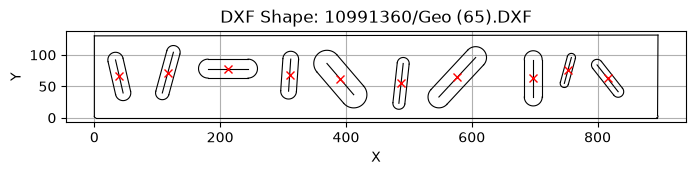

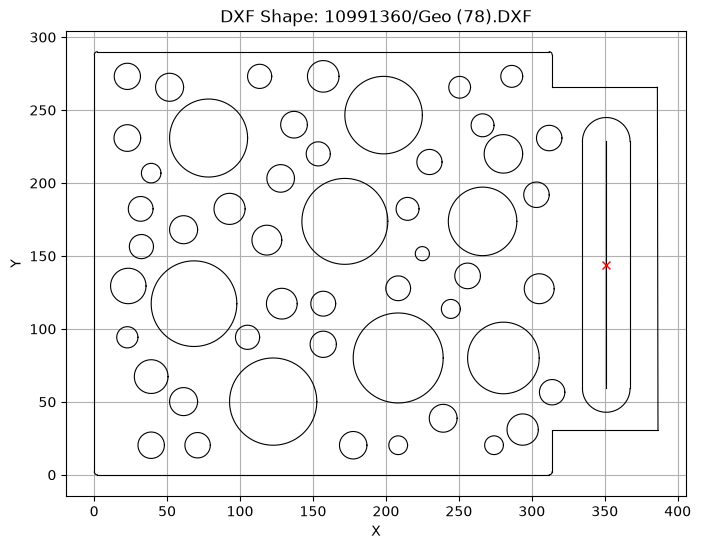

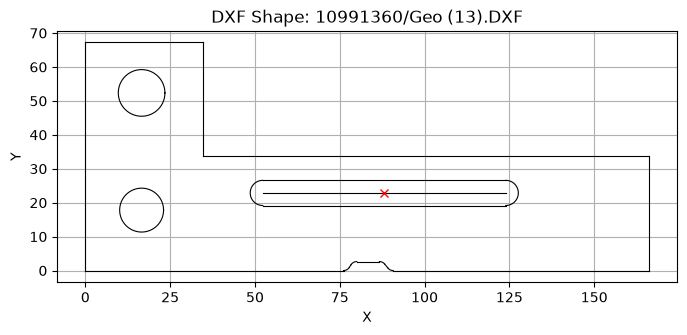

In [6]:
plot_dxf("10991360/Geo (65).DXF")
plot_dxf("10991360/Geo (78).DXF")
plot_dxf("10991360/Geo (13).DXF")

## Point location
#### Test for all DXF files containing "Points" in which layer their points are located

In [7]:
for f in FilePath("../Challenge1/10991360").glob("*.[dD][xX][fF]"):
    points = get_point_context(f)                       
    lines = get_line_context(f) 
    if points or lines:
            flag = "" if len(points) == len(lines) else "   <-- Anzahl verschieden"
            print(f.name, "| POINTs:", points, "| unconnected LINEs:", lines, flag)


Geo (23).DXF | POINTs: [1, 1, 1, 1, 1, 1] | unconnected LINEs: [1, 1, 1, 1, 1, 1] 
Geo (9).DXF | POINTs: [1, 1] | unconnected LINEs: [1, 1] 
Geo (78).DXF | POINTs: [1] | unconnected LINEs: [1] 
Geo (14).DXF | POINTs: [1, 1] | unconnected LINEs: [1, 1] 
Geo (13).DXF | POINTs: [1] | unconnected LINEs: [1] 
Geo (25).DXF | POINTs: [1, 1, 1, 1, 1] | unconnected LINEs: [1, 1, 1, 1, 1] 
Geo (64).DXF | POINTs: [1, 1, 1, 1] | unconnected LINEs: [1, 1, 1, 1] 
Geo (65).DXF | POINTs: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1] | unconnected LINEs: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1] 
Geo (53).DXF | POINTs: [1] | unconnected LINEs: [1] 
Geo (12).DXF | POINTs: [1, 1] | unconnected LINEs: [1, 1] 
Geo (11).DXF | POINTs: [1, 1, 1, 1, 1, 1] | unconnected LINEs: [1, 1, 1, 1, 1, 1] 
Geo (66).DXF | POINTs: [1, 1, 1, 1, 1, 1, 1] | unconnected LINEs: [1, 1, 1, 1, 1, 1, 1] 
Geo (71).DXF | POINTs: [1] | unconnected LINEs: [1] 
Geo (10).DXF | POINTs: [1, 1, 1, 1, 1] | unconnected LINEs: [1, 1, 1, 1, 1] 
Geo (7).DXF | POINTs: [1,

-> all points and lines are located in "scrap"-layers (layer 1)

-> Together with the three plotted DXF-files it's quite clear that "Points" and "unconnected LINEs" are markers for centers of ovals. Taking a closer look on the output we can also observe that the number of POINTs and unconnected LINEs is the same for each file.

For the helper functions and the further EDA this has the following consequences: "Points" are irrelevant for any calculation of cutting length, bounding box or number of holes. "Unconnected lines" (Meaning lines which are not connected to any ARCs, CIRCLEs or other LINEs) are also irrelevant for the cutting process (since they'll be removed with the scrap) and therefore should NOT be taken into account when calculating cutting length.

## Check further DXF problems
1. Overlapping geometries, Duplicates
2. Mirrored entities
3. Protrusions, Gaps
4. Overlapping scrap surfaces

In [8]:
def count_free_endpoints(path, tol=1e-6):
    doc = ezdxf.readfile(path)

    # Same geometry extraction as bridge_gaps()
    lines = [
        LineString(flatten(e))
        for e in doc.modelspace()
        if e.dxftype() in ("LINE", "ARC", "CIRCLE")
        and not (
            e.dxftype() == "LINE"
            and "CENTER" in e.dxf.linetype.upper()
        )
    ]

    endpoints = []

    for i, line in enumerate(lines):
        if line.coords[0] == line.coords[-1]:
            continue

        endpoints.append((i, tuple(line.coords[0])))
        endpoints.append((i, tuple(line.coords[-1])))

    free = []

    for i, p in endpoints:
        connected = any(
            j != i and math.dist(p, q) <= tol
            for j, q in endpoints
        )

        if not connected:
            free.append((i, p))

    return len(free)

def overlap_length(path):
    """Summe der Einzellängen minus Länge der vereinigten Linien (>0: Duplikate/Überlappung)."""
    msp = ezdxf.readfile(path).modelspace()
    lines = [LineString(flatten(e)) for e in msp if e.dxftype() in ("LINE", "ARC", "CIRCLE")]
    return sum(l.length for l in lines) - unary_union(lines).length

attrs, extrusion = Counter(), Counter()
rows = []
for f in sorted(FilePath("../Challenge1/10991360").glob("*.[dD][xX][fF]")):
    doc = ezdxf.readfile(f)
    msp = doc.modelspace()
    for e in msp:
        attrs[(e.dxftype(), e.dxf.layer, e.dxf.linetype, e.dxf.color)] += 1
        if e.dxftype() in ("ARC", "CIRCLE"):
            extrusion[tuple(round(v, 6) for v in e.dxf.extrusion)] += 1
    n_points = len(msp.query("POINT"))
    faces = get_faces(f)
    parts = sum(1 for _, d in faces if d % 2 == 0)
    rows.append({
        "file": f.name,
        "units": doc.units,
        "paperspace": sum(len(l) for l in doc.layouts if l.name != "Model"),
        "overlap_len": overlap_length(f),
        "free_ends_extra": count_free_endpoints(f) - 2 * n_points,
        "face_mismatch": len(faces) - (parts + get_number_of_holes(f)),
        "z_nonzero": sum(1 for e in msp.query("LINE")
                         if abs(e.dxf.start.z) > 1e-9 or abs(e.dxf.end.z) > 1e-9),
    })
chk = pd.DataFrame(rows)

print(attrs)        # Layer/Linientyp/Farbe: nur (…, "0", "Continuous", 7)?
print(extrusion)    # nur (0, 0, 1)?
print(chk.units.value_counts())
print(chk[(chk.overlap_len > 0.01) | (chk.free_ends_extra > 0) | (chk.face_mismatch != 0)
          | (chk.paperspace > 0) | (chk.z_nonzero > 0)])

Counter({('LINE', '0', 'Continuous', 7): 1751, ('CIRCLE', '0', 'Continuous', 7): 530, ('ARC', '0', 'Continuous', 7): 491, ('LINE', '0', 'CENTERX2', 7): 63, ('POINT', '0', 'Continuous', 7): 63})
Counter({(0.0, 0.0, 1.0): 1021})
units
4    80
Name: count, dtype: int64
            file  units  paperspace   overlap_len  free_ends_extra  \
11   Geo (2).DXF      4           0  4.547474e-13                2   
53  Geo (58).DXF      4           0  0.000000e+00                2   
78  Geo (80).DXF      4           0  0.000000e+00                2   

    face_mismatch  z_nonzero  
11              0          0  
53              0          0  
78              0          0  


-> for Geo 58 and 80: gaps have occured between entities

-> for Geo 2: overlapping entities have occured

## Print out these files and their gaps / protrusions

Geo (58).DXF Löcher: 6 [('ARC', 124.194, 145.612, 0.7821), ('LINE', 124.194, 144.83, 0.7821)]


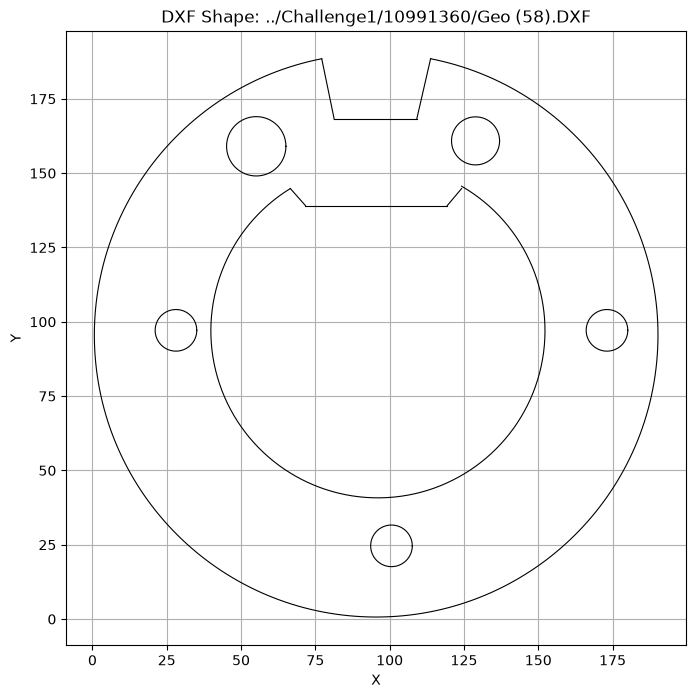

Geo (2).DXF Löcher: 0 [('LINE', 1273.0, -1.0, 1.4142), ('LINE', 1274.0, 0.0, 1.4142)]


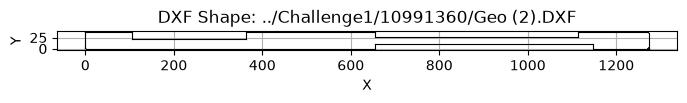

Geo (80).DXF Löcher: 15 []


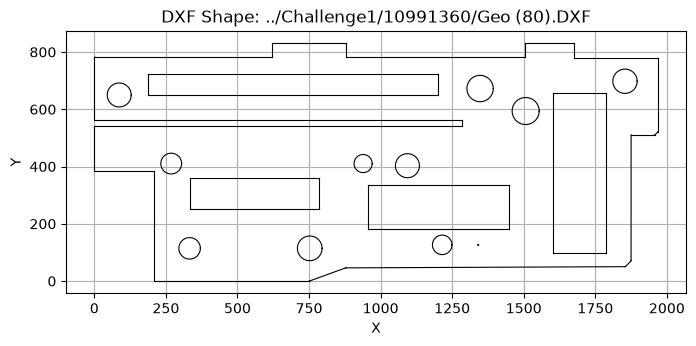

In [9]:
def free_endpoints(path, tol=1e-3):
    msp = ezdxf.readfile(path).modelspace()
    ends = []
    for i, e in enumerate(msp):
        t = e.dxftype()
        if t == "LINE":
            pts = (e.dxf.start, e.dxf.end)
        elif t == "ARC":
            pts = (e.start_point, e.end_point)
        else:
            continue
        ends += [(i, t, p) for p in pts]
    out = []
    for i, t, p in ends:
        d = min((math.dist((p.x, p.y), (q.x, q.y)) for j, _, q in ends if j != i), default=None)
        if d is not None and d > tol:
            out.append((t, round(p.x, 3), round(p.y, 3), round(d, 4)))
    return out

for name in ["Geo (58).DXF", "Geo (2).DXF", "Geo (80).DXF"]:
    p = FilePath("../Challenge1/10991360") / name
    print(name, "Löcher:", get_number_of_holes(p), free_endpoints(p))
    plot_dxf(p)

1. For Geo 58 it's clearly visible, that the inner circle is not closed (upper right corner)

-> Therefore we're adding a helper function "bridge_gaps()" which makes sure that polygonize() tracks all surfaces correctly


2. For Geo 2 we should have a close up on the problematic area, to inspect the problem in more detail

-> print out the problematic area of Geo 2


3. For Geo 80, we don't directly see the problem (where is the gap?). Seems like the tol is still too big

-> print out the problematic area of Geo 80



## 1. Check if added function bridge_gaps() works correctly

In [10]:
def debug_bridges(path):
    doc = ezdxf.readfile(path)
    lines = [LineString(flatten(e)) for e in doc.modelspace()
             if e.dxftype() in ("LINE", "ARC", "CIRCLE")
             and not (e.dxftype() == "LINE" and "CENTER" in e.dxf.linetype.upper())]
    return len(bridge_gaps(lines)) - len(lines)

'''for name in ["Geo (58).DXF", "Geo (2).DXF", "Geo (29).DXF"]:
    p = FilePath("../Challenge1/10991360") / name
    print(name, "| Bridges:", debug_bridges(p),
          "| Holes:", get_number_of_holes(p), "| Parts:", get_number_of_parts(p)[1])'''


folder = FilePath("../Challenge1/10991360")

for p in sorted(folder.glob("*.DXF")):
    print(
        p.name,
        "| Bridges:", debug_bridges(p),
        "| Holes:", get_number_of_holes(p),
        "| Parts:", get_number_of_parts(p)[1]
    )

Geo (1).DXF | Bridges: 0 | Holes: 0 | Parts: 1
Geo (10).DXF | Bridges: 0 | Holes: 5 | Parts: 1
Geo (11).DXF | Bridges: 0 | Holes: 7 | Parts: 1
Geo (12).DXF | Bridges: 0 | Holes: 11 | Parts: 1
Geo (13).DXF | Bridges: 0 | Holes: 3 | Parts: 1
Geo (14).DXF | Bridges: 0 | Holes: 5 | Parts: 1
Geo (15).DXF | Bridges: 0 | Holes: 2 | Parts: 1
Geo (16).DXF | Bridges: 0 | Holes: 13 | Parts: 1
Geo (17).DXF | Bridges: 0 | Holes: 13 | Parts: 1
Geo (18).DXF | Bridges: 0 | Holes: 0 | Parts: 1
Geo (19).DXF | Bridges: 0 | Holes: 0 | Parts: 1
Geo (2).DXF | Bridges: 1 | Holes: 0 | Parts: 3
Geo (20).DXF | Bridges: 0 | Holes: 4 | Parts: 1
Geo (21).DXF | Bridges: 0 | Holes: 4 | Parts: 1
Geo (22).DXF | Bridges: 0 | Holes: 10 | Parts: 1
Geo (23).DXF | Bridges: 0 | Holes: 7 | Parts: 1
Geo (24).DXF | Bridges: 0 | Holes: 15 | Parts: 1
Geo (25).DXF | Bridges: 0 | Holes: 11 | Parts: 1
Geo (26).DXF | Bridges: 0 | Holes: 0 | Parts: 1
Geo (27).DXF | Bridges: 0 | Holes: 9 | Parts: 1
Geo (28).DXF | Bridges: 0 | Holes: 3

-> everything works fine, but for Geo 2 we see that it has clearly a problem with the right part/hole count

## 2. Print the problematic area in Geo 2

Original lines: 22
Bridged lines: 23
Created bridges: 1
Bridge 1: [(1273.0, -1.0), (1274.0, 0.0)]


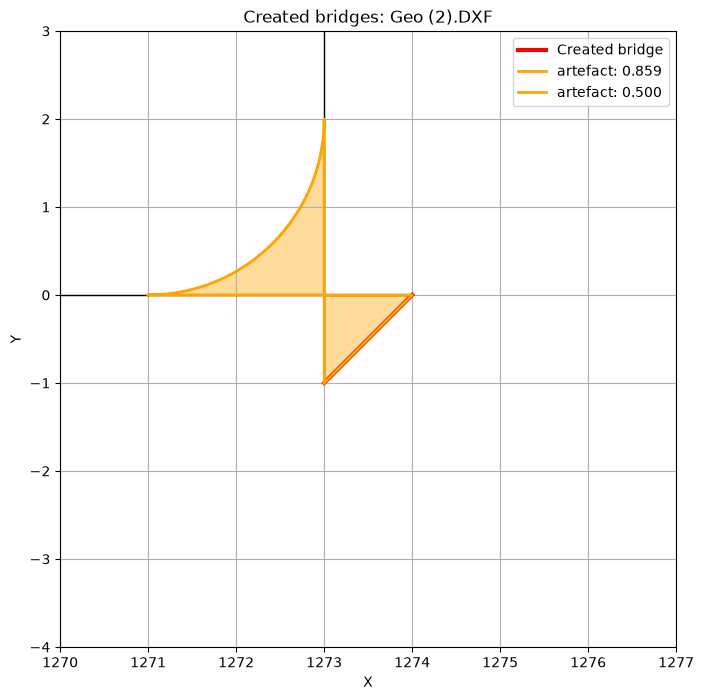

In [11]:
def plot_bridges(path, margin):
    doc = ezdxf.readfile(path)

    # Load original geometry
    lines = [
        LineString(flatten(e))
        for e in doc.modelspace()
        if e.dxftype() in ("LINE", "ARC", "CIRCLE")
        and not (
            e.dxftype() == "LINE"
            and "CENTER" in e.dxf.linetype.upper()
        )
    ]

    # Create bridges
    bridged = bridge_gaps(lines)
    bridges = bridged[len(lines):]

    # Polygonize geometry
    merged = unary_union(bridged)
    polygons, _, _, _ = polygonize_full(merged)

    print("Original lines:", len(lines))
    print("Bridged lines:", len(bridged))
    print("Created bridges:", len(bridges))

    if not bridges:
        print("No bridges created.")
        return

    fig, ax = plt.subplots(figsize=(12, 8))

    # Draw original geometry
    for line in lines:
        x, y = line.xy
        ax.plot(x, y, color="black", linewidth=1)

    # Draw bridges and label them
    for i, bridge in enumerate(bridges):
        x, y = bridge.xy

        ax.plot(
            x, y,
            color="red",
            linewidth=3,
            label="Created bridge" if i == 0 else None
        )

        print(f"Bridge {i+1}: {list(bridge.coords)}")

    # mark small polygons
    for i, poly in enumerate(polygons.geoms):
        if poly.area < 10:
            x, y = poly.exterior.xy
            ax.fill(x, y, color="orange", alpha=0.4)
            ax.plot(x, y, color="orange", linewidth=2,
                    label=f"artefact: {poly.area:.3f}")

    # Zoom to the created bridges
    minx = min(b.bounds[0] for b in bridges)
    miny = min(b.bounds[1] for b in bridges)
    maxx = max(b.bounds[2] for b in bridges)
    maxy = max(b.bounds[3] for b in bridges)

    ax.set_xlim(minx - margin, maxx + margin)
    ax.set_ylim(miny - margin, maxy + margin)

    ax.set_aspect("equal")
    ax.grid(True)
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_title(f"Created bridges: {FilePath(path).name}")
    ax.legend()

    plt.show()

plot_bridges(FilePath("../Challenge1/10991360/Geo (2).DXF"), 3)

Now we observe two areas in Geo 2 (yellow) which are not inside the main part. These "parts" are created by:
1. an ARC inside the main part
2. bridging because of overlapping LINEs

Since we don't have any information about the right geometry of this part, we'll just have to assume the most plausible option.
In this case we think the ARC is not accidentally placed there and should lead to a rounded corner in the cutted part. Instead the outer LINEs are too long and they forgot to remove them. To prevent missinterpretation by the helper functions (get_number_of_holes(), get_cutting_length()) in the EDA, we'll remove these outer LINEs of Geo 2 in the following steps and save the editet DXF-file-collection in a new folder "10991360_editet".

## Edit DXF file (2) and save in a new folder

In [12]:
# Source- and target folder
source = FilePath("../Challenge1/10991360")
target = FilePath("../Challenge1/10991360_editet")

# copy hole folder
shutil.copytree(source, target, dirs_exist_ok=True)

# edit Geo (2).DXF in the new folder
path = target / "Geo (2).DXF"

doc = ezdxf.readfile(path)
msp = doc.modelspace()

# Unnecessary line segments at the corner
segments = [
    ((1271, 0), (1274, 0)),
    ((1273, -1), (1273, 2))
]

# remove LINEs
for e in list(msp.query("LINE")):
    start = (e.dxf.start.x, e.dxf.start.y)
    end = (e.dxf.end.x, e.dxf.end.y)

    for p1, p2 in segments:
        if (
            (math.dist(start, p1) < 0.01 and math.dist(end, p2) < 0.01)
            or
            (math.dist(start, p2) < 0.01 and math.dist(end, p1) < 0.01)
        ):
            msp.delete_entity(e)
            print(f"Entfernt: {start} -> {end}")
            break

# Save under the same file name (target folder)
doc.saveas(path)

Entfernt: (1273.0, 2.0) -> (1273.0, -1.0)
Entfernt: (1271.0, 0.0) -> (1274.0, 0.0)


## Plot the editet Geo 2 & check bridges, parts, holes again

In [13]:
plot_bridges(FilePath("../Challenge1/10991360_editet/Geo (2).DXF"), 3)

for name in ["Geo (58).DXF", "Geo (2).DXF", "Geo (80).DXF"]:
    p = FilePath("../Challenge1/10991360_editet") / name
    print(name, "| Bridges:", debug_bridges(p),
          "| Holes:", get_number_of_holes(p), "| Parts:", get_number_of_parts(p)[1])

Original lines: 20
Bridged lines: 20
Created bridges: 0
No bridges created.
Geo (58).DXF | Bridges: 1 | Holes: 6 | Parts: 1
Geo (2).DXF | Bridges: 0 | Holes: 0 | Parts: 1
Geo (80).DXF | Bridges: 1 | Holes: 15 | Parts: 1


#### -> In the editet dataset no problems occure anymore; holes and parts are calculated correctly; bridges are only necessary for Geo 58 and 80

## 3. Now check the created bridge in Geo 80

Number of bridges: 1
Bridge 1 length: 0.0010000000000000009

Original polygons: 15
Polygons after bridging: 16

Total area before: 353657.41019449994
Total area after: 1355978.701831
Original lines: 58
Bridged lines: 59
Created bridges: 1
Bridge 1: [(752.444, 0.302), (752.444, 0.301)]


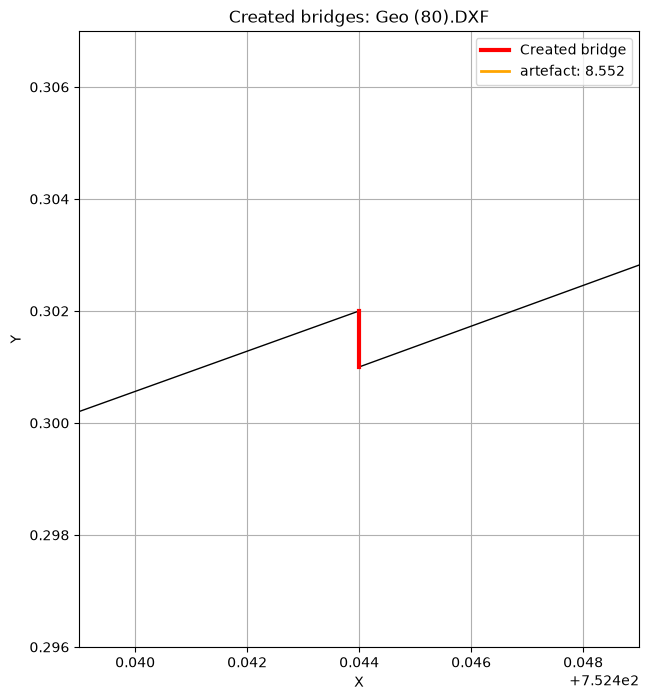

In [14]:
path = FilePath("../Challenge1/10991360/Geo (80).DXF")

doc = ezdxf.readfile(path)

# Load original geometry
lines = [
    LineString(flatten(e))
    for e in doc.modelspace()
    if e.dxftype() in ("LINE", "ARC", "CIRCLE")
    and not (
        e.dxftype() == "LINE"
        and "CENTER" in e.dxf.linetype.upper()
    )
]

# Create bridges
bridged = bridge_gaps(lines)
bridges = bridged[len(lines):]

# Check bridge length
print("Number of bridges:", len(bridges))

for i, bridge in enumerate(bridges):
    print(f"Bridge {i+1} length:", bridge.length)

# Polygonization before bridging
original = polygonize_full(unary_union(lines))[0]

# Polygonization after bridging
after = polygonize_full(unary_union(bridged))[0]

print("\nOriginal polygons:", len(original.geoms))
print("Polygons after bridging:", len(after.geoms))

print("\nTotal area before:", sum(p.area for p in original.geoms))
print("Total area after:", sum(p.area for p in after.geoms))

plot_bridges(FilePath("../Challenge1/10991360/Geo (80).DXF"), 0.005)

The output gives us the following infos:
1. The bridge is very small and hence wasn't shown earlier because the "tol" was too big.
2. The bridge closes a new polygone which tremendously increases the surface area.

This leads us to the assumption, that this bridge is closing the outer contour of the part.
Therefore the bridge is quite important here (as in Geo 58) to calculate the correct area and works exactly as it should.